In [3]:
from torchvision.datasets import OxfordIIITPet

train_data = OxfordIIITPet(root="../data", split="trainval",
                           target_types="binary-category", download=True)
test_data = OxfordIIITPet(root="../data", split="test",
                          target_types="binary-category", download=True)

print("공부용:", len(train_data), "장 / 시험용:", len(test_data), "장")
print("이름표:", train_data.bin_classes)

100%|██████████| 792M/792M [03:02<00:00, 4.34MB/s]   
100%|██████████| 19.2M/19.2M [00:03<00:00, 5.50MB/s]


공부용: 3680 장 / 시험용: 3669 장
이름표: ['Cat', 'Dog']


In [4]:
image, label = train_data[0]
assert label in (0, 1), "이름표가 0 또는 1이어야 해요. 옵션 이름을 다시 확인해 보세요"
print("통과!", train_data.bin_classes[label])

통과! Cat


In [5]:
from collections import Counter

labels = [label for _, label in train_data]   # 3,680장의 이름표만 모으기 (30초쯤 걸려요)
count = Counter(labels)

for idx, name in enumerate(train_data.bin_classes):
    print(f"{name}: {count[idx]}장 ({count[idx] / len(labels):.1%})")

Cat: 1188장 (32.3%)
Dog: 2492장 (67.7%)


In [6]:
assert count[0] + count[1] == len(train_data), "고양이 + 개 = 전체 장수여야 해요"
print("통과!")

통과!


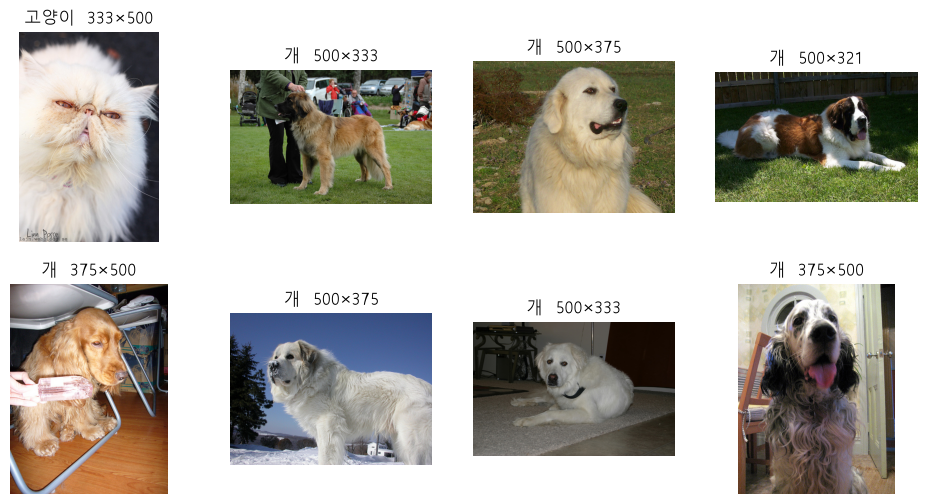

In [7]:
import random
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"

names = ["고양이", "개"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flat:
    idx = random.randrange(len(train_data))
    image, label = train_data[idx]
    ax.imshow(image)
    ax.set_title(f"{names[label]}  {image.size[0]}×{image.size[1]}")
    ax.axis("off")
plt.show()